# Processing - ClinVar conflicting classifications

Turns the EDA handoff (`eda_decisions.yml`) into training-ready feature matrices for two model families: **catboost** (native categoricals) and **gbm** (ordinal-encoded, for LightGBM / XGBoost / HistGradientBoosting). Library code lives in `dsprep/` (copied, unmodified); project logic in `processing_clinvar.py`. Cells follow `../AGENT.md` (no `CLAUDE.md` in the repo; user's choice).

**User decisions (all questions answered, no defaults taken):** keep `CLNDN`, `CLNDISDB` and `CLNSIGINCL` (EDA: check with user); group-stratified split by gene (EDA: stratified); feature sets catboost + gbm; record class weights. No rows have a missing target.

## Setup

In [1]:
import os
from pathlib import Path
import kagglehub

# Load KAGGLE_API_TOKEN from the repo-root .env
for line in (Path.cwd().parent / ".env").read_text().splitlines():
    key, _, value = line.strip().partition("=")
    if key and not key.startswith("#"):
        os.environ.setdefault(key, value.strip().strip("\"'"))

path = kagglehub.dataset_download("kevinarvai/clinvar-conflicting")
DATA_FILE = Path(path) / "clinvar_conflicting.csv"
print(DATA_FILE)

C:\Users\Or\.cache\kagglehub\datasets\kevinarvai\clinvar-conflicting\versions\2\clinvar_conflicting.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import dsprep as dp
import processing_clinvar as pc

import warnings
warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

TARGET = "CLASS"
TASK = "binary"
SEED = 42
FEATURE_SETS = ["catboost", "gbm"]
print("dsprep", dp.__version__)

dsprep 0.2.0


## 1. Decisions review
Load the EDA handoff, list every step with its status and the open questions, then record the user's answers as overrides so the record shows recommended vs. done.

In [3]:
df_raw = pd.read_csv(DATA_FILE, low_memory=False)
dec = dp.load_decisions("eda_decisions.yml")
print(df_raw.shape)
dp.decisions_summary(dec)[["section", "step", "column", "status", "reason"]]

(65188, 46)


,section,step,column,status,reason
0,cleaning,parsing_fixes,cDNA_position,recommended,numbers stored as text because indels carry ra...
1,cleaning,parsing_fixes,CDS_position,recommended,numbers stored as text because indels carry ra...
2,cleaning,parsing_fixes,Protein_position,recommended,numbers stored as text because indels carry ra...
3,cleaning,parsing_fixes,EXON,recommended,two numbers packed into one string
4,cleaning,parsing_fixes,INTRON,recommended,two numbers packed into one string
...,...,...,...,...,...
57,recommendations,redundant_pairs,"[ALT, Allele]",recommended,
58,recommendations,redundant_pairs,"[SYMBOL, Feature]",recommended,
59,recommendations,redundant_pairs,"[AF_ESP, AF_EXAC]",recommended,
60,recommendations,redundant_pairs,"[SIFT, PolyPhen]",recommended,


In [4]:
for q in dp.open_questions(dec):
    print("-", q)

- When is a variant scored: on existing ClinVar records (keep CLNDN / CLNDISDB) or at first submission (drop them as leakage)?
- Keep CLNSIGINCL (167 rows, a clinical-significance field)? Default: drop.
- Primary validation: random stratified (variants in known genes) or grouped by gene (unseen genes)?
- leakage for CLNDN: {'evidence': 'names collected per submission; 22% conflicting with 1 name vs 40% with 4+ (AUC 0.57)'} ()
- leakage for CLNDISDB: {'evidence': 'same information as CLNDN as database IDs'} ()
- leakage for CLNSIGINCL: {'evidence': 'clinical-significance field; 167 rows, 41% conflicting vs 25%'} ()


In [5]:
KEEP = ["CLNDN", "CLNDISDB", "CLNSIGINCL", "CLNVI"]
dec = dp.apply_overrides(dec, {
    "recommendations.leakage": [{"column": c, "evidence": "user chose to keep", "verdict": "keep"} for c in KEEP],
    "validation.split": "group_stratified",
    "validation.stratify_on": [TARGET],
    "open_questions": [],
})
pd.DataFrame(dec["_overrides"])

,key,eda_value,user_value
0,recommendations.leakage,"[{'column': 'CLNDN', 'evidence': 'names collec...","[{'column': 'CLNDN', 'evidence': 'user chose t..."
1,validation.split,stratified,group_stratified
2,validation.stratify_on,[CLASS],[CLASS]
3,open_questions,[When is a variant scored: on existing ClinVar...,[]


**Findings**


- The EDA left three open questions; all were answered by the user and recorded as overrides:
  - Leakage: the verdicts for `CLNDN`, `CLNDISDB` and `CLNSIGINCL` change from "check with user" to **keep**. Risk, stated once: `CLNSIGINCL` is itself a clinical-significance field and `CLNDN` / `CLNDISDB` grow with the number of submitters, so scores may be optimistic for freshly submitted variants.
  - Split: `stratified` -> **`group_stratified`** by `SYMBOL`.
  - `open_questions` cleared.
- No missing targets, so no unlabeled set.

## 2. Cleaning
`apply_cleaning` re-applies the EDA steps to the raw data and drops the recommended columns. The `manual` parsing fixes (position ranges, `n/total` strings) are done by `pc.parse_fields`, then `pc.add_domain_features` adds the stateless features listed in the EDA's manual-treatment section.

In [6]:
df, clean_log = dp.apply_cleaning(df_raw, dec)
print(df_raw.shape, "->", df.shape)
clean_log

(65188, 46) -> (65188, 29)


,step,column,action,n_affected,note
0,parsing_fixes,cDNA_position,manual,None,take the first integer of the text ('943-944' ...
1,parsing_fixes,CDS_position,manual,None,take the first integer of the text ('943-944' ...
2,parsing_fixes,Protein_position,manual,None,take the first integer of the text ('943-944' ...
3,parsing_fixes,EXON,manual,None,split 'n/total' into EXON_num and EXON_total
4,parsing_fixes,INTRON,manual,None,split 'n/total' into INTRON_num and INTRON_total
5,drop_columns,POS,dropped,None,"genomic coordinate, part of the key"
6,drop_columns,CLNHGVS,dropped,None,unique identifier (key as a string)
7,drop_columns,Allele,dropped,None,same as ALT in VEP notation
8,drop_columns,Feature,dropped,None,"transcript ID, one-to-one with SYMBOL for 98.4..."
9,drop_columns,Feature_type,dropped,None,near-constant (99.98% Transcript)


In [7]:
df = pc.prepare(df)
new_cols = [c for c in df.columns if c not in df_raw.columns]
print(df.shape, f"{len(new_cols)} new columns:")
print(new_cols)
df[["REF", "ALT", "snv_change", "len_diff", "Amino_acids", "aa_ref", "aa_alt", "codon_pos",
    "ORIGIN", "origin_n_bits", "CLNVI_sources", "MC_terms", "EXON_frac", "gene_n_variants"]].head(6)

(65188, 58) 31 new columns:
['EXON_num', 'EXON_total', 'EXON_frac', 'INTRON_num', 'INTRON_total', 'INTRON_frac', 'AF_ESP_zero', 'AF_EXAC_zero', 'AF_TGP_zero', 'AF_max', 'AF_n_cohorts', 'origin_germline', 'origin_somatic', 'origin_inherited', 'origin_paternal', 'origin_maternal', 'origin_de_novo', 'origin_n_bits', 'ref_len', 'alt_len', 'len_diff', 'snv_change', 'is_transition', 'aa_ref', 'aa_alt', 'aa_to_stop', 'codon_pos', 'CLNVI_sources', 'MC_terms', 'CLNSIGINCL_sig', 'gene_n_variants']


,REF,ALT,snv_change,len_diff,Amino_acids,aa_ref,aa_alt,codon_pos,ORIGIN,origin_n_bits,CLNVI_sources,MC_terms,EXON_frac,gene_n_variants
0,G,C,G>C,0,E/D,E,D,3.0,1,1,UniProtKB_(protein),missense_variant,1.000000,3.0
1,G,A,G>A,0,P/L,P,L,2.0,1,1,OMIM_Allelic_Variant|UniProtKB_(protein),missense_variant,1.000000,1.0
2,A,G,A>G,0,I/T,I,T,2.0,35,3,OMIM_Allelic_Variant|UniProtKB_(protein),missense_variant|5_prime_UTR_variant,0.500000,1.0
3,G,A,G>A,0,G/S,G,S,1.0,33,2,OMIM_Allelic_Variant|UniProtKB_(protein),missense_variant,0.142857,50.0
4,G,T,G>T,0,G/C,G,C,1.0,33,2,OMIM_Allelic_Variant|UniProtKB_(protein),missense_variant,0.142857,50.0
5,G,C,G>C,0,G/R,G,R,1.0,33,2,UniProtKB_(protein),missense_variant,0.142857,50.0


In [8]:
check = pd.DataFrame({
    "non_null": df[new_cols].notna().sum(),
    "n_unique": df[new_cols].nunique(),
    "example": df[new_cols].apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
check

,non_null,n_unique,example
EXON_num,56295,336,1.0
EXON_total,56295,87,1.0
EXON_frac,56295,2101,1.0
INTRON_num,8803,207,6.0
INTRON_total,8803,83,27.0
INTRON_frac,8803,1268,0.222222
AF_ESP_zero,65188,2,0
AF_EXAC_zero,65188,2,0
AF_TGP_zero,65188,2,0
AF_max,65188,5517,0.1066


**Findings**


- `apply_cleaning` dropped the 17 recommended columns (identifiers, near-constant, empty, redundant); no rows were removed (the EDA found no duplicates or invalid values). 65,188 rows x 29 columns.
- The 5 `manual` parsing fixes in the log are done by `pc.parse_fields`: positions get the first number of a range; `EXON` / `INTRON` become `_num`, `_total`, `_frac`.
- 31 engineered columns, all stateless and row-level (except `gene_n_variants`, a count over the full frame with no target):
  - AF zero flags, `AF_max`, `AF_n_cohorts`
  - six ORIGIN bit flags and `origin_n_bits`
  - REF/ALT lengths, `len_diff`, `snv_change` (12 SNV substitutions + `non_snv`), `is_transition`
  - `aa_ref`, `aa_alt`, `aa_to_stop`, `codon_pos` (1-3)
  - reshaped list columns `CLNVI_sources` (345 combinations), `MC_terms`, `CLNSIGINCL_sig` (167 rows)

## 3. Split
Group-stratified 70 / 15 / 15: every gene (`SYMBOL`) sits in exactly one split, and the target share is balanced. The 16 mitochondrial variants have no gene and form one group. Gene size (`gene_n_variants`) is computed on the full frame before splitting; it uses no target and is known from ClinVar itself at scoring time.

In [9]:
splits = dp.make_split(df, how="group_stratified", sizes=(0.7, 0.15, 0.15),
                       group_col=pc.GROUP_COL, stratify_col=TARGET, seed=SEED)
dp.split_report(splits, target=TARGET, group_col=pc.GROUP_COL)

,split,rows,share,target_dist,groups_also_in_train
0,train,48279,0.740612,"{0: 0.748, 1: 0.252}",NaN
1,val,9107,0.139704,"{0: 0.74, 1: 0.26}",0.0
2,test,7802,0.119685,"{0: 0.755, 1: 0.245}",0.0


In [10]:
big = ["TTN", "BRCA2", "ATM", "APC", "BRCA1"]
pd.DataFrame({name: s[pc.GROUP_COL].isin(big).groupby(s[pc.GROUP_COL]).size().reindex(big).fillna(0).astype(int)
              for name, s in splits.items()})

,train,val,test
SYMBOL,,,
TTN,2765,0,0
BRCA2,0,1934,0
ATM,1909,0,0
APC,1228,0,0
BRCA1,1075,0,0


**Findings**


- Actual shares are **74.1 / 14.0 / 12.0%** (48,279 / 9,107 / 7,802 rows) instead of 70/15/15. Whole genes must stay together, and a few genes are huge: BRCA2 alone is 1,934 rows, 21% of the validation set. TTN, ATM, APC and BRCA1 all landed in train.
- The target is balanced across splits: 25.2% / 26.0% / 24.5% positives. No gene appears in more than one split (`groups_also_in_train` = 0). The 16 MT variants without a gene share the group `__no_gene__`.
- This measures generalization to **unseen genes**, the pessimistic case. Because a single gene can dominate val or test, expect noisy metrics; in the modeling step use StratifiedGroupKFold CV (`dp.make_cv_folds(train, how="group_stratified", group_col="SYMBOL", stratify_col="CLASS")`) rather than relying on one val score.

## 4. Target

In [11]:
tp = dp.TargetProcessor(TASK, positive_class=1)
y = {name: tp.fit_transform(s[TARGET]) if name == "train" else tp.transform(s[TARGET]) for name, s in splits.items()}
class_weights = tp.class_weights(y["train"])
print(tp.describe())
print("positive share:", {k: round(float(v.mean()), 4) for k, v in y.items()})
print("class weights (balanced, from train):", class_weights)

{'task': 'binary', 'mode': 'auto', 'classes': ['0', '1'], 'positive_class': '1'}
positive share: {'train': 0.2516, 'val': 0.2605, 'test': 0.2453}
class weights (balanced, from train): {0.0: 0.6681104868395561, 1.0: 1.9871172209417187}


**Findings**


- Binary, positive class 1, no transform. 25.2% positives in train.
- Balanced class weights from train: {0: 0.668, 1: 1.987}. Saved in `processing_record.yml`; whether to use them is a modeling choice (PR-AUC is the primary metric either way).

## 5. Features
`suggest_specs` gives the EDA-derived starting point; the specs actually used are in `processing_clinvar.py`. Main differences from the suggestion, and why:
- Raw `REF`, `ALT`, `Amino_acids`, `Codons`, `EXON`, `INTRON` and `ORIGIN` are replaced by parsed / engineered columns (lengths, SNV change, amino-acid pair, codon position, origin bits, exon fraction).
- `SYMBOL` is the split group, so it is **not** a feature: under a gene-grouped split, test genes are never seen in training, so any gene encoding would be useless on test while overfitting on train. Gene-level information enters through `LoFtool` and `gene_n_variants`.
- List columns are reshaped so each has one token type (`CLNVI` -> database sources, `MC` -> SO term names, `CLNSIGINCL` -> significance labels).

In [12]:
for fam in FEATURE_SETS:
    s = dp.suggest_specs(dec, model_family=fam)
    print(f"--- suggested ({fam}):", {k: (list(v) if isinstance(v, dict) else v) for k, v in s.items()
                                     if k in ("categorical", "lists", "fold_columns")})

--- suggested (catboost): {'fold_columns': ['group_col', 'time_col'], 'categorical': ['CHROM', 'CLNVC', 'ORIGIN', 'IMPACT', 'BAM_EDIT', 'SIFT', 'PolyPhen', 'REF', 'ALT', 'SYMBOL', 'EXON', 'INTRON', 'Amino_acids', 'Codons'], 'lists': ['CLNDISDB', 'CLNDN', 'CLNSIGINCL', 'CLNVI', 'MC', 'Consequence']}
--- suggested (gbm): {'fold_columns': ['group_col', 'time_col'], 'categorical': ['CHROM', 'CLNVC', 'ORIGIN', 'IMPACT', 'BAM_EDIT', 'SIFT', 'PolyPhen', 'REF', 'ALT', 'SYMBOL', 'EXON', 'INTRON', 'Amino_acids', 'Codons'], 'lists': ['CLNDISDB', 'CLNDN', 'CLNSIGINCL', 'CLNVI', 'MC', 'Consequence']}


In [13]:
fps, X = {}, {}
for fs in FEATURE_SETS:
    fp = pc.build_feature_processor(fs, task=TASK)
    X[("train", fs)] = fp.fit_transform(splits["train"], y["train"])
    for name in ("val", "test"):
        X[(name, fs)] = fp.transform(splits[name])
    fps[fs] = fp
    print(fs, {name: X[(name, fs)].shape for name in splits})

catboost {'train': (48279, 126), 'val': (9107, 126), 'test': (7802, 126)}


gbm {'train': (48279, 126), 'val': (9107, 126), 'test': (7802, 126)}


In [14]:
print("unused input columns (dropped):", fps["gbm"].unused_columns_)
fps["gbm"].log

unused input columns (dropped): ['REF', 'ALT', 'CLNSIGINCL', 'MC', 'ORIGIN', 'CLASS', 'SYMBOL', 'Amino_acids', 'Codons']


,step,processor,column,action,detail
0,num,NumericProcessor,CADD_PHRED,missing_indicator,train missing rate 1.564%
1,num,NumericProcessor,LoFtool,missing_indicator,train missing rate 7.005%
2,cat,CategoricalProcessor,CHROM,group_rare,3 levels (942 rows) -> __OTHER__
3,cat,CategoricalProcessor,CHROM,ordinal,22 codes
4,cat,CategoricalProcessor,CLNVC,group_rare,4 levels (259 rows) -> __OTHER__
5,cat,CategoricalProcessor,CLNVC,ordinal,4 codes
6,cat,CategoricalProcessor,IMPACT,ordinal,4 codes
7,cat,CategoricalProcessor,SIFT,ordinal,5 codes
8,cat,CategoricalProcessor,PolyPhen,group_rare,1 levels (3 rows) -> __OTHER__
9,cat,CategoricalProcessor,PolyPhen,ordinal,5 codes


In [15]:
fd = {fs: fp.feature_dictionary() for fs, fp in fps.items()}
fd["gbm"].groupby(["processor", "source"]).size().rename("n_features").reset_index()

,processor,source,n_features
0,CategoricalProcessor,BAM_EDIT,1
1,CategoricalProcessor,CHROM,1
2,CategoricalProcessor,CLNVC,1
3,CategoricalProcessor,IMPACT,1
4,CategoricalProcessor,PolyPhen,1
5,CategoricalProcessor,SIFT,1
6,CategoricalProcessor,aa_alt,1
7,CategoricalProcessor,aa_ref,1
8,CategoricalProcessor,snv_change,1
9,ListProcessor,CLNDISDB,3


In [16]:
print("catboost cat_features:", fps["catboost"].cat_features())
X[("train", "catboost")].head(3)

catboost cat_features: ['CHROM', 'CLNVC', 'IMPACT', 'SIFT', 'PolyPhen', 'BAM_EDIT', 'snv_change', 'aa_ref', 'aa_alt']


,AF_ESP,AF_EXAC,AF_TGP,AF_ESP_zero,AF_EXAC_zero,AF_TGP_zero,AF_max,AF_n_cohorts,CADD_PHRED,CADD_PHRED__missing,LoFtool,LoFtool__missing,BLOSUM62,STRAND,cDNA_position,EXON_num,EXON_total,EXON_frac,INTRON_num,INTRON_total,INTRON_frac,origin_germline,origin_somatic,origin_inherited,origin_paternal,origin_maternal,origin_de_novo,origin_n_bits,ref_len,alt_len,...,MC_terms__has_intron_variant,MC_terms__has_5_prime_utr_variant,MC_terms__has_nonsense,MC_terms__has_frameshift_variant,MC_terms__has_3_prime_utr_variant,MC_terms__has_splice_donor_variant,MC_terms__has_2kb_upstream_variant,MC_terms__has_splice_acceptor_variant,MC_terms__n_other,Consequence__missing,Consequence__len,Consequence__n_unique,Consequence__has_missense_variant,Consequence__has_synonymous_variant,Consequence__has_intron_variant,Consequence__has_splice_region_variant,Consequence__has_stop_gained,Consequence__has_frameshift_variant,Consequence__has_5_prime_utr_variant,Consequence__has_splice_donor_variant,Consequence__has_inframe_deletion,Consequence__has_3_prime_utr_variant,Consequence__has_splice_acceptor_variant,Consequence__n_other,CLNSIGINCL_sig__missing,CLNSIGINCL_sig__len,CLNSIGINCL_sig__n_unique,CLNSIGINCL_sig__has_pathogenic,CLNSIGINCL_sig__has_likely_pathogenic,CLNSIGINCL_sig__n_other
1,0.0,0.00000,0.0,1.0,1.0,1.0,0.00000,0.0,31.0,0,NaN,1,-3.0,-1.0,523.0,4.0,4.0,1.000000,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0,0,0,0,0,0,0,0,0.0,0,1.0,1.0,1,0,0,0,0,0,0,0,0,0,0,0.0,1,NaN,NaN,0,0,0.0
2,0.0,0.00001,0.0,1.0,0.0,1.0,0.00001,1.0,28.1,0,NaN,1,-1.0,-1.0,632.0,6.0,12.0,0.500000,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,3.0,1.0,1.0,...,0,1,0,0,0,0,0,0,0.0,0,1.0,1.0,1,0,0,0,0,0,0,0,0,0,0,0.0,1,NaN,NaN,0,0,0.0
3,0.0,0.00000,0.0,1.0,1.0,1.0,0.00000,0.0,22.5,0,NaN,1,NaN,1.0,132.0,1.0,7.0,0.142857,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,1.0,2.0,1.0,1.0,...,0,0,0,0,0,0,0,0,0.0,0,1.0,1.0,1,0,0,0,0,0,0,0,0,0,0,0.0,1,NaN,NaN,0,0,0.0


**Findings**


- Both feature sets have **126 columns** (train 48,279 rows):
  - 35 numeric (33 inputs plus missing indicators for `CADD_PHRED` and `LoFtool`)
  - 9 categoricals
  - 82 list features (`CLNDN` 34, `Consequence` 15, `MC_terms` 14, `CLNVI_sources` 7, `CLNSIGINCL_sig` 6, `CLNVI` 3, `CLNDISDB` 3)
- They differ only in categorical encoding.
  - **catboost:** raw strings; pass `cat_features` (`CHROM`, `CLNVC`, `IMPACT`, `SIFT`, `PolyPhen`, `BAM_EDIT`, `snv_change`, `aa_ref`, `aa_alt`).
  - **gbm:** ordinal codes, with `IMPACT` in its natural order (MODIFIER < LOW < MODERATE < HIGH) and rare levels grouped (CHROM 3 levels, CLNVC 4, PolyPhen 1, BAM_EDIT FAILED, aa_ref / aa_alt indel combinations).
- NaN is kept in both, since tree models handle it natively. The structurally missing fields (SIFT / PolyPhen as `__MISSING__` level; BLOSUM62, positions as NaN) keep their "not applicable" meaning.
- Dropped as inputs (replaced by engineered columns or used as the group): `REF`, `ALT`, `Amino_acids`, `Codons`, `MC`, `ORIGIN`, `CLNSIGINCL`, `SYMBOL`.
- `CLNDN` multi-hot keeps the 30 most frequent disease names out of 3,224 in train. Many are gene-specific (e.g. hereditary cancer, cardiomyopathy), so they partly act as gene proxies.

## 6. Screening
Constant, duplicate and highly correlated features plus a single-feature leakage scan, on the gbm training matrix. Report only; nothing is dropped without approval.

In [17]:
scr = dp.screening_report(X[("train", "gbm")], y["train"], TASK)
for name, table in scr.items():
    print(f"--- {name}: {len(table)} rows")

--- constant: 16 rows
--- duplicates: 5 rows
--- correlated: 26 rows
--- leakage: 123 rows


In [18]:
scr["constant"]

,feature,n_unique,top_share
0,origin_germline,2,0.9995
1,origin_somatic,2,0.9953
2,origin_inherited,2,0.9965
3,origin_paternal,2,0.9976
4,origin_maternal,2,0.9971
5,origin_de_novo,2,0.9959
6,CLNDN__missing,1,1.0000
7,CLNDISDB__missing,1,1.0000
8,MC_terms__n_other,2,0.9993
9,Consequence__missing,1,1.0000


In [19]:
scr["duplicates"]

,feature,duplicate_of
0,CLNDISDB__missing,CLNDN__missing
1,CLNDISDB__len,CLNDN__len
2,MC_terms__n_unique,MC_terms__len
3,Consequence__missing,CLNDN__missing
4,Consequence__n_unique,Consequence__len


In [20]:
scr["correlated"]

,feature_a,feature_b,corr
0,CLNDN__len,CLNDISDB__len,1.000000
1,EXON_total,INTRON_total,1.000000
2,Consequence__len,Consequence__n_unique,1.000000
3,MC_terms__len,MC_terms__n_unique,1.000000
4,CLNVI__len,CLNVI__n_unique,0.999994
5,CLNDN__n_unique,CLNDISDB__len,0.999989
6,CLNDN__len,CLNDN__n_unique,0.999989
7,CLNDISDB__len,CLNDISDB__n_unique,0.999898
8,CLNDN__len,CLNDISDB__n_unique,0.999898
9,CLNDN__n_unique,CLNDISDB__n_unique,0.999887


In [21]:
scr["leakage"].head(10)

,feature,kind,measure,score,suspect
0,AF_EXAC_zero,numeric,auc,0.5827,False
1,AF_n_cohorts,numeric,auc,0.5820,False
2,CLNVI__missing,numeric,auc,0.5816,False
3,CLNDN__has_hereditary_cancer-predisposing_synd...,numeric,auc,0.5721,False
4,CLNVI_sources__has_illumina_clinical_services_...,numeric,auc,0.5643,False
5,CLNDISDB__n_unique,numeric,auc,0.5620,False
6,CLNDISDB__len,numeric,auc,0.5620,False
7,CLNDN__len,numeric,auc,0.5620,False
8,CLNDN__n_unique,numeric,auc,0.5620,False
9,CLNDN__n_other,numeric,auc,0.5601,False


**Findings**


- **Constant** (3, always 0 because the column is never missing): `CLNDN__missing`, `CLNDISDB__missing`, `Consequence__missing`. Safe to drop.
- **Exact duplicates** (4): `CLNDISDB__missing`, `CLNDISDB__len` (= `CLNDN__len`), `MC_terms__n_unique`, `Consequence__n_unique`. Safe to drop.
- **Near-constant** (13 more at >= 99.5% one value): ORIGIN bits and `CLNSIGINCL_sig` features. They are rare but informative (EDA: 36-45% conflicting for maternal / paternal / somatic); keep.
- **Highly correlated** (26 pairs > 0.95): mostly parallel encodings of the same thing (`CLNDN` vs `CLNDISDB` counts, `MC_terms` vs `Consequence` flags, `EXON_*` vs `INTRON_*` totals). Harmless for trees; prune for interpretability if wanted.
- **Leakage scan:** no suspect. The strongest single feature is `AF_EXAC_zero` at AUC 0.58, in line with the EDA.
- **Nothing was dropped.** The 7 constant / duplicate columns are listed as a recommendation for the user to approve.

## 7. Validation

In [22]:
dp.check_frames({name: X[(name, "catboost")] for name in splits}, cat_features=fps["catboost"].cat_features())

,split,issue,detail
0,train,NaN present,"18 columns, e.g. ['CADD_PHRED', 'LoFtool', 'BL..."
1,val,NaN present,"17 columns, e.g. ['CADD_PHRED', 'LoFtool', 'BL..."
2,test,NaN present,"17 columns, e.g. ['CADD_PHRED', 'LoFtool', 'BL..."


In [23]:
dp.check_frames({name: X[(name, "gbm")] for name in splits})

,split,issue,detail
0,train,NaN present,"18 columns, e.g. ['CADD_PHRED', 'LoFtool', 'BL..."
1,val,NaN present,"17 columns, e.g. ['CADD_PHRED', 'LoFtool', 'BL..."
2,test,NaN present,"17 columns, e.g. ['CADD_PHRED', 'LoFtool', 'BL..."


In [24]:
drift = dp.drift_report(X[("train", "gbm")], X[("test", "gbm")], exclude=fps["gbm"].target_encoded_features())
print(drift["flag"].value_counts().to_dict())
drift.head(10)

{'ok': 104, 'moderate': 13, 'major': 9}


,feature,psi,flag
0,gene_n_variants,1.489181,major
1,CLNSIGINCL_sig__len,1.285742,major
2,EXON_total,0.683409,major
3,CLNDN__has_dilated_cardiomyopathy_1g,0.430301,major
4,CLNDN__has_limb-girdle_muscular_dystrophy__typ...,0.422800,major
5,CHROM__ord,0.391844,major
6,LoFtool,0.361482,major
7,CLNDN__has_ataxia-telangiectasia_syndrome,0.324727,major
8,INTRON_total,0.252952,major
9,CLNDN__has_familial_adenomatous_polyposis_1,0.200611,moderate


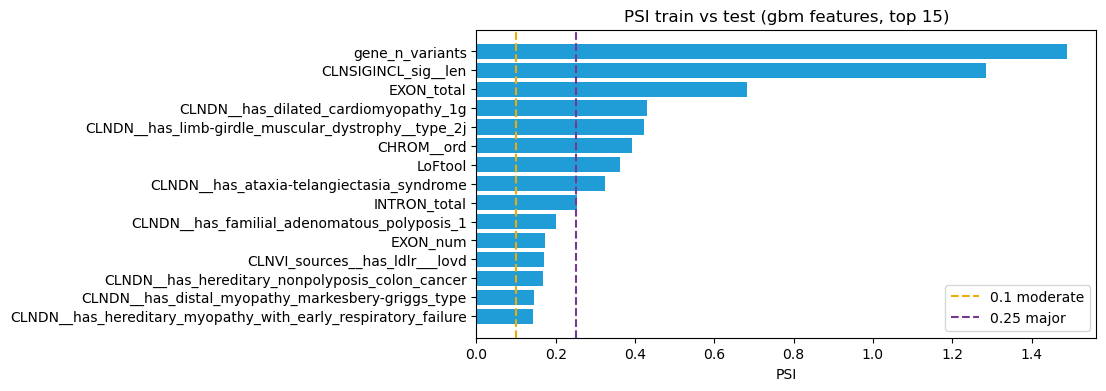

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
top = drift.head(15).iloc[::-1]
ax.barh(top["feature"], top["psi"], color="#209dd7")
ax.axvline(0.1, ls="--", color="#ecad0a", label="0.1 moderate")
ax.axvline(0.25, ls="--", color="#753991", label="0.25 major")
ax.set(title="PSI train vs test (gbm features, top 15)", xlabel="PSI")
ax.legend()
plt.show()

In [26]:
base = dp.baseline_check(X[("train", "gbm")], y["train"], X[("val", "gbm")], y["val"], TASK, seed=SEED)
base

,model,roc_auc,pr_auc
0,dummy,0.500000,0.260459
1,hist_gb,0.834226,0.632520


**Findings**


- Frames are consistent: same columns and dtypes across splits, no inf. NaN appears only in the expected columns (CADD, LoFtool, BLOSUM62, positions, exon / intron).
- **Drift train vs test (PSI):** 104 ok, 13 moderate, 9 major. All the major ones are gene-level by construction of the group split:
  - `gene_n_variants` 1.49, because test holds a different set of genes.
  - `CLNSIGINCL_sig__len` 1.29: very rare feature, unstable PSI.
  - `EXON_total`, `INTRON_total`, `LoFtool`, `CHROM`: gene properties.
  - Gene-specific `CLNDN` disease flags.

  This is the shift the split is meant to test, not a pipeline bug. Variant-level features (AF, CADD, IMPACT, consequence flags) are stable.
- **Baseline on val:** the dummy model scores PR-AUC 0.260; a quick HistGradientBoosting scores ROC-AUC **0.834** and PR-AUC **0.633**. The features carry real signal and nothing looks leaked (not near-perfect).

## 8. Outputs

In [27]:
frames = {f"X_{name}_{fs}": X[(name, fs)] for (name, fs) in X}
frames.update({f"y_{name}": y[name].to_frame(TARGET) for name in splits})
frames.update({f"groups_{name}": splits[name][[pc.GROUP_COL]] for name in splits})
paths = dp.save_frames(frames, "data/processed")
for fs, fp in fps.items():
    paths[f"feature_processor_{fs}"] = dp.save_object(fp, f"models/feature_processor_{fs}.joblib")
    fd[fs].to_csv(f"feature_dictionary_{fs}.csv", index=False)
    paths[f"feature_dictionary_{fs}"] = f"feature_dictionary_{fs}.csv"
paths["target_processor"] = dp.save_object(tp, "models/target_processor.joblib")
pd.Series(paths)

X_train_catboost                data/processed\X_train_catboost.parquet
X_val_catboost                    data/processed\X_val_catboost.parquet
X_test_catboost                  data/processed\X_test_catboost.parquet
X_train_gbm                          data/processed\X_train_gbm.parquet
X_val_gbm                              data/processed\X_val_gbm.parquet
X_test_gbm                            data/processed\X_test_gbm.parquet
y_train                                  data/processed\y_train.parquet
y_val                                      data/processed\y_val.parquet
y_test                                    data/processed\y_test.parquet
groups_train                        data/processed\groups_train.parquet
groups_val                            data/processed\groups_val.parquet
groups_test                          data/processed\groups_test.parquet
feature_processor_catboost     models/feature_processor_catboost.joblib
feature_dictionary_catboost             feature_dictionary_catbo

In [28]:
record = dp.write_processing_record(
    "processing_record.yml", decisions=dec, cleaning_log=clean_log, target=tp,
    split={"how": "group_stratified", "sizes": [0.7, 0.15, 0.15], "group_col": pc.GROUP_COL,
           "stratify_col": TARGET, "seed": SEED},
    feature_processors=fps, dropped_features=[], outputs=paths,
    notes=[f"class_weights (balanced, train): {class_weights}",
           "SYMBOL is the split group and not a feature",
           "gene_n_variants computed on the full frame before splitting (no target used)",
           "CV in the modeling step: refit build_feature_processor() per fold; folds grouped by SYMBOL"])
print(record)

processing_record.yml


**Findings**


- `data/processed/`: `X_{train,val,test}_{catboost,gbm}.parquet`, `y_{train,val,test}.parquet`, `groups_{split}.parquet` (SYMBOL, for grouped CV).
- `models/`: fitted `feature_processor_catboost.joblib`, `feature_processor_gbm.joblib`, `target_processor.joblib`.
- `feature_dictionary_{catboost,gbm}.csv`, `processing_record.yml` (overrides, cleaning log, split, feature logs, class weights).